# Letra
A partir del juego de datos alturas recabado en clase, realizar un modelo lineal para predecir
la altura de los hijos. En este ejercicio deberas tomar las decisiones que te parezcan adecuadas y
contarnos tus conclusiones, es decir, no es olbigatorio usar todos los datos, ni todas las variables.
Una vez elegido el modelo, escribirlo y explicar qué significa cada uno de sus coeficientes.

# Exploracion de los datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
alturas_2025 = pd.read_csv("Alturas2025.csv")
alturas_2026 = pd.read_csv("Alturas2026.csv")

print("Datos 2025:", alturas_2025.shape)
print("Datos 2026:", alturas_2026.shape)

Datos 2025: (39, 5)
Datos 2026: (45, 5)


In [3]:
print("Datos 2025:")
display(alturas_2025.head())

print("Datos 2026:")
display(alturas_2026.head())

Datos 2025:


,Respuesta número,Altura estudiante del curso (en cm),Altura mamá (en cm),Altura papá (en cm),sexo
0,1,157.0,153.0,168.0,Femenino
1,2,170.0,174.0,185.0,Femenino
2,3,182.0,164.0,181.0,Masculino
3,4,176.0,159.0,181.0,Masculino
4,5,164.0,164.0,170.0,Femenino


Datos 2026:


,Response number,(Altura estudiante) Altura de la persona (estudiante del curso) en cm,(sexo) Sexo biológico de la persona,(Altura padre) Altura padre en cm,(Altura madre) Altura madre en cm
0,1,175.0,Masculino,185,165
1,2,176.0,Masculino,175,154
2,3,177.0,Masculino,180,171
3,4,170.0,NaN,175,180
4,5,184.0,Masculino,183,165


In [4]:
print("Columnas 2025:")
for columna in alturas_2025.columns:
    print("-", columna)

print("\nColumnas 2026:")
for columna in alturas_2026.columns:
    print("-", columna)

Columnas 2025:
- Respuesta número
- Altura estudiante del curso (en cm)
- Altura mamá (en cm)
- Altura papá (en cm)
- sexo

Columnas 2026:
- Response number
- (Altura estudiante) Altura de la persona (estudiante del curso) en cm
- (sexo) Sexo biológico de la persona
- (Altura padre) Altura padre en cm
- (Altura madre) Altura madre en cm


In [5]:
print("Informacion 2025:")
alturas_2025.info()

print("\nInformacion 2026:")
alturas_2026.info()

Informacion 2025:
<class 'pandas.DataFrame'>
RangeIndex: 39 entries, 0 to 38
Data columns (total 5 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Respuesta número                     39 non-null     int64  
 1   Altura estudiante del curso (en cm)  39 non-null     float64
 2   Altura mamá (en cm)                  38 non-null     float64
 3   Altura papá (en cm)                  38 non-null     float64
 4   sexo                                 39 non-null     str    
dtypes: float64(3), int64(1), str(1)
memory usage: 1.7 KB

Informacion 2026:
<class 'pandas.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 5 columns):
 #   Column                                                                 Non-Null Count  Dtype  
---  ------                                                                 --------------  -----  
 0   Response number                                         

In [6]:
print("Valores faltantes 2025:")
print(alturas_2025.isna().sum())

print("\nValores faltantes 2026:")
print(alturas_2026.isna().sum())

Valores faltantes 2025:
Respuesta número                       0
Altura estudiante del curso (en cm)    0
Altura mamá (en cm)                    1
Altura papá (en cm)                    1
sexo                                   0
dtype: int64

Valores faltantes 2026:
Response number                                                          0
(Altura estudiante) Altura de la persona (estudiante del curso) en cm    1
(sexo) Sexo biológico de la persona                                      1
(Altura padre) Altura padre en cm                                        0
(Altura madre) Altura madre en cm                                        0
dtype: int64


In [7]:
print("Filas con datos faltantes - 2025:")
display(
    alturas_2025[
        alturas_2025.isna().any(axis=1)
    ]
)

print("Filas con datos faltantes - 2026:")
display(
    alturas_2026[
        alturas_2026.isna().any(axis=1)
    ]
)

Filas con datos faltantes - 2025:


,Respuesta número,Altura estudiante del curso (en cm),Altura mamá (en cm),Altura papá (en cm),sexo
7,8,170.0,NaN,NaN,Masculino


Filas con datos faltantes - 2026:


,Response number,(Altura estudiante) Altura de la persona (estudiante del curso) en cm,(sexo) Sexo biológico de la persona,(Altura padre) Altura padre en cm,(Altura madre) Altura madre en cm
3,4,170.0,NaN,175,180
35,36,NaN,Masculino,169,155


In [8]:
print("Resumen 2025:")
display(alturas_2025.describe())

print("Resumen 2026:")
display(alturas_2026.describe())

Resumen 2025:


,Respuesta número,Altura estudiante del curso (en cm),Altura mamá (en cm),Altura papá (en cm)
count,39.000000,39.000000,38.000000,38.000000
mean,20.000000,173.346154,165.763158,175.868421
std,11.401754,8.735254,5.185396,6.498112
min,1.000000,157.000000,153.000000,160.000000
25%,10.500000,167.000000,163.000000,171.250000
50%,20.000000,174.000000,165.000000,175.500000
75%,29.500000,180.500000,169.750000,180.750000
max,39.000000,188.000000,177.000000,190.000000


Resumen 2026:


,Response number,(Altura estudiante) Altura de la persona (estudiante del curso) en cm,(Altura padre) Altura padre en cm,(Altura madre) Altura madre en cm
count,45.000000,44.000000,45.000000,45.000000
mean,23.000000,176.363636,178.244444,164.311111
std,13.133926,7.883132,7.589333,5.724041
min,1.000000,157.000000,158.000000,154.000000
25%,12.000000,173.750000,174.000000,160.000000
50%,23.000000,177.500000,179.000000,165.000000
75%,34.000000,181.250000,183.000000,168.000000
max,45.000000,190.000000,198.000000,180.000000


In [9]:
print("Sexo 2025:")
print(
    alturas_2025["sexo"].value_counts(
        dropna=False
    )
)

print("\nSexo 2026:")
print(
    alturas_2026[
        "(sexo) Sexo biológico de la persona"
    ].value_counts(
        dropna=False
    )
)

Sexo 2025:
sexo
Masculino    27
Femenino     12
Name: count, dtype: int64

Sexo 2026:
(sexo) Sexo biológico de la persona
Masculino    37
Femenino      7
NaN           1
Name: count, dtype: int64


# Limpieza y unificacion de los datos

In [10]:
alturas_2025 = alturas_2025.rename(columns={
    "Respuesta número": "id_respuesta",
    "Altura estudiante del curso (en cm)": "altura_hijo",
    "Altura mamá (en cm)": "altura_madre",
    "Altura papá (en cm)": "altura_padre",
    "sexo": "sexo"
})

alturas_2026 = alturas_2026.rename(columns={
    "Response number": "id_respuesta",
    "(Altura estudiante) Altura de la persona (estudiante del curso) en cm": "altura_hijo",
    "(sexo) Sexo biológico de la persona": "sexo",
    "(Altura padre) Altura padre en cm": "altura_padre",
    "(Altura madre) Altura madre en cm": "altura_madre"
})

In [11]:
alturas_2025["año"] = 2025
alturas_2026["año"] = 2026

columnas = [
    "id_respuesta",
    "altura_hijo",
    "altura_madre",
    "altura_padre",
    "sexo",
    "año"
]

alturas_2025 = alturas_2025[columnas]
alturas_2026 = alturas_2026[columnas]

display(alturas_2025.head())
display(alturas_2026.head())

,id_respuesta,altura_hijo,altura_madre,altura_padre,sexo,año
0,1,157.0,153.0,168.0,Femenino,2025
1,2,170.0,174.0,185.0,Femenino,2025
2,3,182.0,164.0,181.0,Masculino,2025
3,4,176.0,159.0,181.0,Masculino,2025
4,5,164.0,164.0,170.0,Femenino,2025


,id_respuesta,altura_hijo,altura_madre,altura_padre,sexo,año
0,1,175.0,165,185,Masculino,2026
1,2,176.0,154,175,Masculino,2026
2,3,177.0,171,180,Masculino,2026
3,4,170.0,180,175,NaN,2026
4,5,184.0,165,183,Masculino,2026


In [12]:
datos = pd.concat(
    [alturas_2025, alturas_2026],
    ignore_index=True
)

print("Cantidad total:", len(datos))

datos.head()

Cantidad total: 84


,id_respuesta,altura_hijo,altura_madre,altura_padre,sexo,año
0,1,157.0,153.0,168.0,Femenino,2025
1,2,170.0,174.0,185.0,Femenino,2025
2,3,182.0,164.0,181.0,Masculino,2025
3,4,176.0,159.0,181.0,Masculino,2025
4,5,164.0,164.0,170.0,Femenino,2025


In [13]:
datos_base = datos.dropna( #elimina las filas donde la altura hijo sea NaN
    subset=["altura_hijo"]
).copy()

datos_padres = datos_base.dropna(  
    subset=[
        "altura_madre",
        "altura_padre"
    ]
).copy()

datos_completos = datos_padres.dropna(
    subset=["sexo"]
).copy()

datos_completos["sexo"] = (
    datos_completos["sexo"]
    .str.strip()
)

print("Datos originales:", len(datos))
print("Con altura del hijo:", len(datos_base))
print("Con padre y madre:", len(datos_padres))
print("Con padre, madre y sexo:", len(datos_completos))

Datos originales: 84
Con altura del hijo: 83
Con padre y madre: 82
Con padre, madre y sexo: 81


In [14]:
display(
    datos_padres[
        [
            "altura_hijo",
            "altura_madre",
            "altura_padre"
        ]
    ].describe()
)

print("\nSexo:")
print(datos_completos["sexo"].value_counts())

,altura_hijo,altura_madre,altura_padre
count,82.000000,82.000000,82.000000
mean,175.006098,165.097561,177.256098
std,8.414601,5.419694,7.154056
min,157.000000,153.000000,158.000000
25%,170.000000,160.250000,172.000000
50%,176.500000,165.000000,178.000000
75%,181.000000,169.000000,182.000000
max,190.000000,180.000000,198.000000



Sexo:
sexo
Masculino    62
Femenino     19
Name: count, dtype: int64


mean - promedio

std - desviacion estandar

25% -> significa que el 25% de los datos esta por debajo de 170 en el caso de altura hijo

# Analisis

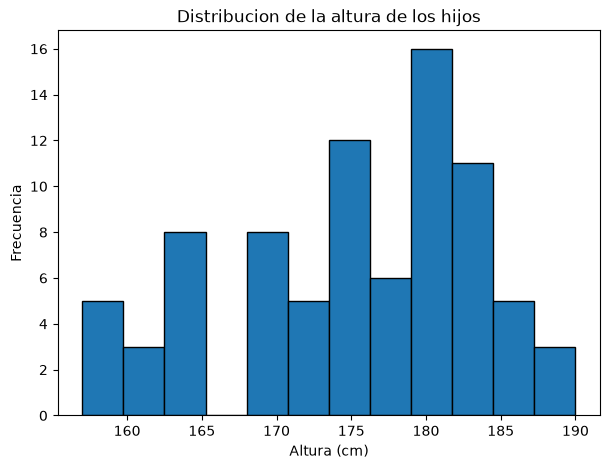

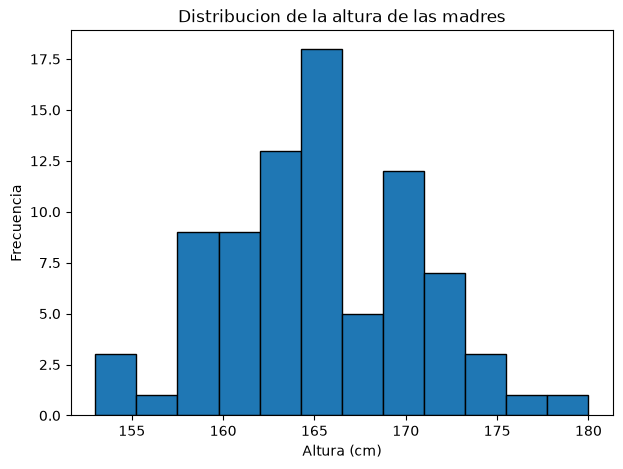

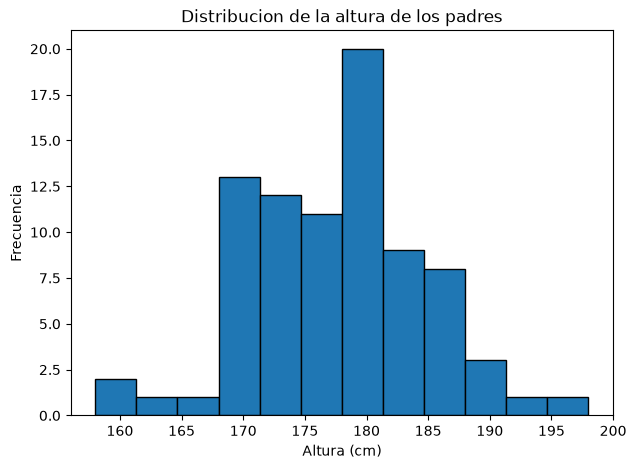

In [15]:
plt.figure(figsize=(7, 5))
plt.hist(
    datos_padres["altura_hijo"],
    bins=12,
    edgecolor="black"
)
plt.xlabel("Altura (cm)")
plt.ylabel("Frecuencia")
plt.title("Distribucion de la altura de los hijos")
plt.show()

plt.figure(figsize=(7, 5))
plt.hist(
    datos_padres["altura_madre"],
    bins=12,
    edgecolor="black"
)
plt.xlabel("Altura (cm)")
plt.ylabel("Frecuencia")
plt.title("Distribucion de la altura de las madres")
plt.show()

plt.figure(figsize=(7, 5))
plt.hist(
    datos_padres["altura_padre"],
    bins=12,
    edgecolor="black"
)
plt.xlabel("Altura (cm)")
plt.ylabel("Frecuencia")
plt.title("Distribucion de la altura de los padres")
plt.show()

In [16]:
resumen_sexo = datos_completos.groupby("sexo")[
    [
        "altura_hijo",
        "altura_madre",
        "altura_padre"
    ]
].mean() #promedio

resumen_sexo

,altura_hijo,altura_madre,altura_padre
sexo,,,
Femenino,163.289474,165.315789,176.894737
Masculino,178.677419,164.790323,177.403226


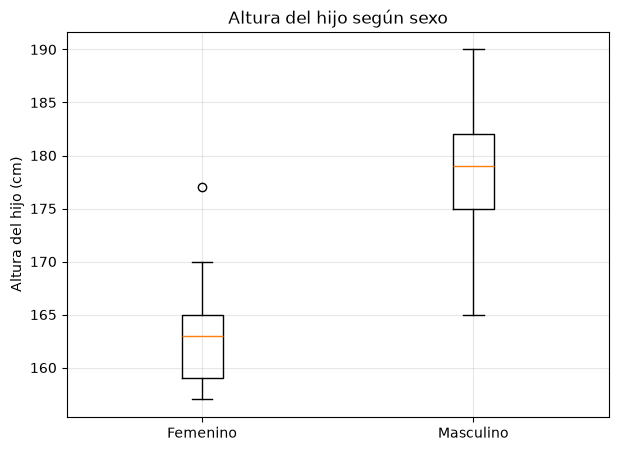

In [17]:
altura_femenino = datos_completos[
    datos_completos["sexo"] == "Femenino"
]["altura_hijo"]

altura_masculino = datos_completos[
    datos_completos["sexo"] == "Masculino"
]["altura_hijo"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [
        altura_femenino,
        altura_masculino
    ],
    tick_labels=[
        "Femenino",
        "Masculino"
    ]
)

plt.ylabel("Altura del hijo (cm)")
plt.title("Altura del hijo según sexo")
plt.grid(alpha=0.3)

plt.show()

La linea naranja dentro del cuadrado es la mediana ( el valor que deja aprox el 50% de los datos por debajo y el 50% de los datos por encima)

La parte inferior de la caja corresponde aprox al 25% y la parte superior al 75%

El circulo es un valor atipico dentro de los datos



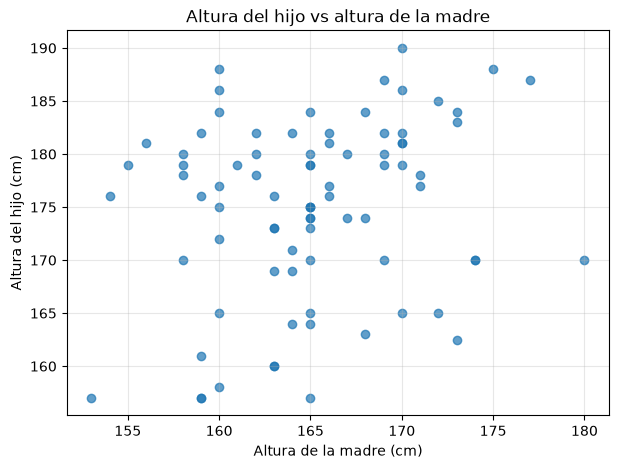

In [18]:
plt.figure(figsize=(7, 5))

plt.scatter(
    datos_padres["altura_madre"],
    datos_padres["altura_hijo"],
    alpha=0.7
)

plt.xlabel("Altura de la madre (cm)")
plt.ylabel("Altura del hijo (cm)")
plt.title("Altura del hijo vs altura de la madre")
plt.grid(alpha=0.3)

plt.show()

Esto lo realizamos para ver si encontramos alguna relacion con respecto a la altura de la madre, se queria ver alguna tendencia en los puntos pero solo se encontro una dispersion, por lo que la altura de la madre por si sola no parece explicar demasiado.

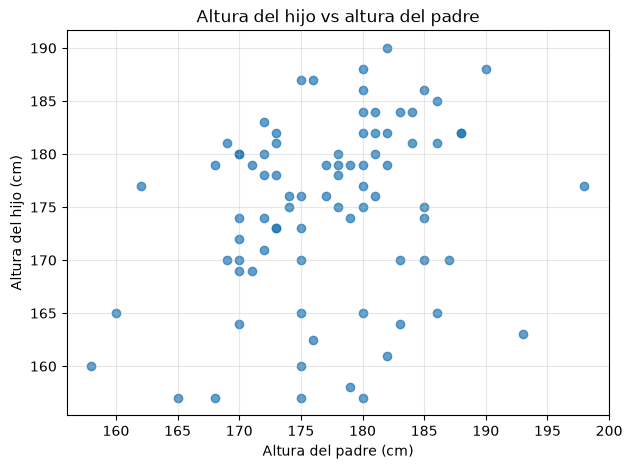

In [19]:
plt.figure(figsize=(7, 5))

plt.scatter(
    datos_padres["altura_padre"],
    datos_padres["altura_hijo"],
    alpha=0.7
)

plt.xlabel("Altura del padre (cm)")
plt.ylabel("Altura del hijo (cm)")
plt.title("Altura del hijo vs altura del padre")
plt.grid(alpha=0.3)

plt.show()

Esto lo realizamos para ver si encontramos alguna relacion con respecto a la altura del padre, se queria ver alguna tendencia en los puntos pero solo se encontro una dispersion, por lo que la altura de la madre por si sola no parece explicar demasiado.

In [20]:
correlaciones = datos_padres[
    [
        "altura_hijo",
        "altura_madre",
        "altura_padre"
    ]
].corr()

correlaciones

,altura_hijo,altura_madre,altura_padre
altura_hijo,1.000000,0.214932,0.270170
altura_madre,0.214932,1.000000,0.073219
altura_padre,0.270170,0.073219,1.000000


Esto es una matriz de correlacion, la cual nos dice que tan fuerte es la relacion lineal entre cada par de variables.

- valor cerca de 1 es una relacion fuerte
- valor cerca de 0 poca relacion

In [21]:
for sexo in [
    "Femenino",
    "Masculino"
]:

    grupo = datos_completos[
        datos_completos["sexo"] == sexo
    ]

    print(f"\n{sexo}")

    print(
        grupo[
            [
                "altura_hijo",
                "altura_madre",
                "altura_padre"
            ]
        ].corr()["altura_hijo"]
    )


Femenino
altura_hijo     1.000000
altura_madre    0.654989
altura_padre    0.472276
Name: altura_hijo, dtype: float64

Masculino
altura_hijo     1.000000
altura_madre    0.374087
altura_padre    0.363105
Name: altura_hijo, dtype: float64


Como antes obtuvimos valores muy bajos, separamos en sexo y se obtuvo mejores valores, esto nos dice que mezclar ambos sexos nos oculta informacion.

In [22]:
print("Promedios por año:")

display(
    datos_padres.groupby("año")[
        [
            "altura_hijo",
            "altura_madre",
            "altura_padre"
        ]
    ].mean()
)

print("\nCantidad por sexo y año:")

display(
    pd.crosstab(
        datos_completos["año"],
        datos_completos["sexo"]
    )
)

print("\nAltura del hijo por año y sexo:")

display(
    datos_completos.groupby(
        ["año", "sexo"]
    )["altura_hijo"].agg(
        ["count", "mean", "std"]
    )
)

Promedios por año:


,altura_hijo,altura_madre,altura_padre
año,,,
2025,173.434211,165.763158,175.868421
2026,176.363636,164.522727,178.454545



Cantidad por sexo y año:


sexo,Femenino,Masculino
año,,
2025,12,26
2026,7,36



Altura del hijo por año y sexo:


count        mean       std
año  sexo                                  
2025 Femenino      12  163.541667  4.914997
     Masculino     26  178.000000  6.019967
2026 Femenino       7  162.857143  6.817345
     Masculino     36  179.166667  4.759952

# Construccion de modelos
- A: madre + padre
- B: sexo
- C: madre + padre + sexo 

In [23]:
datos_modelo = datos_completos.copy()

datos_modelo["sexo_masculino"] = (
    datos_modelo["sexo"] == "Masculino"
).astype(int)

display(
    datos_modelo[
        [
            "sexo",
            "sexo_masculino"
        ]
    ].head()
)

,sexo,sexo_masculino
0,Femenino,0
1,Femenino,0
2,Masculino,1
3,Masculino,1
4,Femenino,0


Esto en necesario porque para la regresion lineal necesita operar con numeros, no puede ustilizar los string

In [24]:
train = (
    datos_modelo
    .groupby(
        "sexo",
        group_keys=False
    )
    .sample(
        frac=0.8,
        random_state=42
    )
)

validacion = datos_modelo.drop(
    train.index
)

print("Entrenamiento:", len(train))
print("Validacion:", len(validacion))

print("\nEntrenamiento:")
print(train["sexo"].value_counts())

print("\nValidacion:")
print(validacion["sexo"].value_counts())

Entrenamiento: 65
Validacion: 16

Entrenamiento:
sexo
Masculino    50
Femenino     15
Name: count, dtype: int64

Validacion:
sexo
Masculino    12
Femenino      4
Name: count, dtype: int64


Separamos el conjunto en dos partes, una para entrenar el modelo y otro para validarlo (igual como hicimos en aprendizaje automatico)

In [25]:
def ajustar_regresion(X, y):
    # convertimos las variables predictoras X en un array y las forzamos a que sean tipo float
    X = np.asarray(X, dtype=float)
    # convertimos la variable objetivo en un array para poder trabajar matematicamente con ella
    y = np.asarray(y, dtype=float)
    # agregamos una columna de 1s al cominezo de X, esa columna representa el intercepto b del modelo y = b + w1*x1 + w2*x2 + ...
    X_diseno = np.column_stack([np.ones(len(X)), X])
    #calculamos los coeficientes mediante minimos cuadrados, se busca los valores b, w1, w2... que miniminizan 
    #la suma de los errores al cuadrado entre los valores reales y las predicciones del modelo
    #np.linalg.lstsq devuelve varios resultados por eso se utiliza [0]
    coeficientes = np.linalg.lstsq(X_diseno, y, rcond=None)[0]

    return coeficientes


def predecir_regresion(X, coeficientes):
    # multiplicamos la matriz X por la matriz de coeficientes
    
    X = np.asarray(X, dtype=float)

    X_diseno = np.column_stack([np.ones(len(X)), X])
    # el operador @ realiza una multiplicacion matricial
    return (X_diseno @ coeficientes)


def calcular_mse(y_real, y_pred):
    #calculamos el error de cada observacion. luego lo elevamos al cuadrado y finalmente hacemos el promedio
    
    y_real = np.asarray(y_real)
    y_pred = np.asarray(y_pred)

    return np.mean((y_real - y_pred) ** 2)


def calcular_r2(y_real, y_pred):
    # comparamos el error de nuestro modelo contra el error que tendriamos si simplemente predijeramos siempre el promedio.

    y_real = np.asarray(y_real)
    y_pred = np.asarray(y_pred)

    ss_res = np.sum((y_real - y_pred) ** 2)

    ss_tot = np.sum((y_real - np.mean(y_real)) ** 2)

    return (1 - ss_res / ss_tot)

Se utiliza minimos cuadrados porque queremos encontrar los coeficientes de la regresion que hagan las predicciones esten lo mas cerca posible de los valores reales. Elevamos los errores al cuadrado para evitar que positivos y negativos se cancelen y para penalizar mas los errores garndes. Ademas, en el modelo gaussiano que usamos en el curso, minimizar cuadrados es equivalente a estimar los coeficientes por maxima verosimilitud.

MSE -> el error cuadradatico medio mide que tan lejos estan las predicciones de los valores reales, penalizando los errores mas grande. Cuanto mas chico, mejor.

R^2 -> mide cuanto de variabilidad de los datos logra explicar el modelo. Cuanto mas cerca de 1, mejor.



# Modelo A

In [26]:
variables_A = ["altura_madre", "altura_padre"]

X_train_A = train[variables_A]
X_val_A = validacion[variables_A]

y_train = train["altura_hijo"]
y_val = validacion["altura_hijo"]

coef_A = ajustar_regresion(X_train_A, y_train)

pred_train_A = predecir_regresion(X_train_A, coef_A)

pred_val_A = predecir_regresion(X_val_A, coef_A)

mse_train_A = calcular_mse(y_train, pred_train_A)

mse_val_A = calcular_mse(y_val, pred_val_A)

r2_train_A = calcular_r2(y_train, pred_train_A)

r2_val_A = calcular_r2(y_val, pred_val_A)

print("Modelo A - Padres")
print("------------------")
print(f"MSE Train: {mse_train_A:.3f}")
print(f"MSE Validacion: {mse_val_A:.3f}")
print(f"R² Train: {r2_train_A:.3f}")
print(f"R² Validacion: {r2_val_A:.3f}")

Modelo A - Padres
------------------
MSE Train: 58.860
MSE Validacion: 74.122
R² Train: 0.122
R² Validacion: 0.124


# Modelo B

In [27]:
variables_B = ["sexo_masculino"]

X_train_B = train[variables_B]
X_val_B = validacion[variables_B]

coef_B = ajustar_regresion(X_train_B, y_train)

pred_train_B = predecir_regresion(X_train_B, coef_B)

pred_val_B = predecir_regresion(X_val_B, coef_B)

mse_train_B = calcular_mse(y_train, pred_train_B)

mse_val_B = calcular_mse(y_val, pred_val_B)

r2_train_B = calcular_r2(y_train, pred_train_B)

r2_val_B = calcular_r2(y_val, pred_val_B)

print("Modelo B - Sexo")
print("----------------")
print(f"MSE Train: {mse_train_B:.3f}")
print(f"MSE Validacion: {mse_val_B:.3f}")
print(f"R² Train: {r2_train_B:.3f}")
print(f"R² Validacion: {r2_val_B:.3f}")

Modelo B - Sexo
----------------
MSE Train: 27.979
MSE Validacion: 28.296
R² Train: 0.582
R² Validacion: 0.666


# Modelo C

In [28]:
variables_C = ["altura_madre", "altura_padre", "sexo_masculino"]

X_train_C = train[variables_C]
X_val_C = validacion[variables_C]

coef_C = ajustar_regresion(X_train_C, y_train)

pred_train_C = predecir_regresion(X_train_C, coef_C)

pred_val_C = predecir_regresion(X_val_C, coef_C)

mse_train_C = calcular_mse(y_train, pred_train_C)

mse_val_C = calcular_mse(y_val, pred_val_C)

r2_train_C = calcular_r2(y_train, pred_train_C)

r2_val_C = calcular_r2(y_val, pred_val_C)

print("Modelo C - Padres + Sexo")
print("------------------------")
print(f"MSE Train: {mse_train_C:.3f}")
print(f"MSE Validacion: {mse_val_C:.3f}")
print(f"R² Train: {r2_train_C:.3f}")
print(f"R² Validacion: {r2_val_C:.3f}")

Modelo C - Padres + Sexo
------------------------
MSE Train: 19.299
MSE Validacion: 17.828
R² Train: 0.712
R² Validacion: 0.789


In [29]:
resultados_modelos = pd.DataFrame({
    "Modelo": ["Padres", "Sexo", "Padres + Sexo"],

    "MSE Train": [mse_train_A, mse_train_B, mse_train_C],

    "MSE Validacion": [mse_val_A, mse_val_B, mse_val_C],

    "R² Train": [r2_train_A, r2_train_B, r2_train_C],

    "R² Validacion": [r2_val_A, r2_val_B, r2_val_C]
})

resultados_modelos

,Modelo,MSE Train,MSE Validacion,R² Train,R² Validacion
0,Padres,58.860107,74.121625,0.121522,0.124400
1,Sexo,27.979282,28.295644,0.582414,0.665743
2,Padres + Sexo,19.298705,17.828321,0.711970,0.789394


In [30]:
print("b:", coef_C[0])

print("\nCoeficientes:")

for variable, coeficiente in zip(variables_C,coef_C[1:]):
    print(variable,":",coeficiente)

b: 49.80095707500334

Coeficientes:
altura_madre : 0.42595724277442215
altura_padre : 0.24526412534926806
sexo_masculino : 14.98034437759975


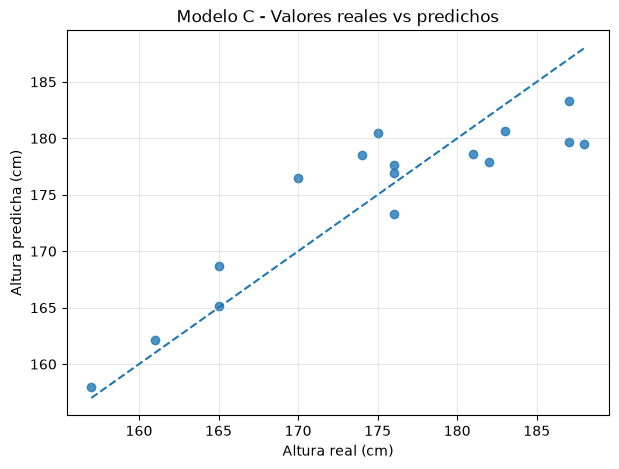

In [31]:
plt.figure(figsize=(7, 5))

plt.scatter(y_val, pred_val_C, alpha=0.8)

minimo = min(y_val.min(), pred_val_C.min())

maximo = max(y_val.max(), pred_val_C.max())

plt.plot([minimo, maximo], [minimo, maximo], linestyle="--")

plt.xlabel("Altura real (cm)")
plt.ylabel("Altura predicha (cm)")
plt.title("Modelo C - Valores reales vs predichos")
plt.grid(alpha=0.3)

plt.show()

Los valores predichos se encuentra, en general, cercanos a la recta punteada (prediccion perfecta), lo que indica que el modelo logra representar de una manera razonablemente bien la altura de los hijos. Sin embargo, se observan algunos casos donde hay diferencia entre la prediccion y el valor real, especialmente en ciertos valores de mayot altura.

# Comprobacion y modelo final

En esta seccion hacemos validacion cruzada para comprobar los resultados obtenidos, ya que son pocos datos los que tenemos. Finalmente, se ajusta nuevamente utilizando todos los datos disponibles para obtener sus coeficientes definitivos.

In [32]:
def crear_folds_estratificados(datos, k=5, random_state=42):

    rng = np.random.default_rng(random_state)

    folds = [
        []
        for _ in range(k)
    ]

    for _, grupo in datos.groupby("sexo"):

        indices = (grupo.index.to_numpy().copy())

        rng.shuffle(indices)

        partes = np.array_split(indices, k)

        for i, parte in enumerate(partes):
            folds[i].extend(
                parte.tolist()
            )

    return [np.array(fold) for fold in folds]

In [33]:
def evaluar_validacion_cruzada(datos, variables, k=5, random_state=42):

    folds = crear_folds_estratificados(datos, k=k, random_state=random_state)

    mse_folds = []
    r2_folds = []

    indices_totales = datos.index.to_numpy()

    for indices_val in folds:

        indices_val_set = set(indices_val)

        indices_train = [
            indice
            for indice in indices_totales
            if indice not in indices_val_set
        ]

        train_fold = datos.loc[
            indices_train
        ]

        val_fold = datos.loc[
            indices_val
        ]

        coeficientes = ajustar_regresion(train_fold[variables], train_fold["altura_hijo"])

        predicciones = predecir_regresion(val_fold[variables], coeficientes)

        mse_folds.append(calcular_mse(val_fold["altura_hijo"], predicciones))

        r2_folds.append(calcular_r2(val_fold["altura_hijo"], predicciones))

    return (np.array(mse_folds), np.array(r2_folds))

In [34]:
modelos = {
    "Padres": variables_A,
    "Sexo": variables_B,
    "Padres + Sexo": variables_C
}

resultados_cv = []

for nombre, variables in modelos.items():

    mse_cv, r2_cv = evaluar_validacion_cruzada(datos_modelo, variables, k=5, random_state=42)

    resultados_cv.append({
        "Modelo": nombre,
        "MSE promedio": np.mean(mse_cv),
        "MSE std": np.std(mse_cv),
        "R² promedio": np.mean(r2_cv)
    })

resultados_cv = pd.DataFrame(
    resultados_cv
)

resultados_cv

,Modelo,MSE promedio,MSE std,R² promedio
0,Padres,69.154113,18.763325,-0.043589
1,Sexo,29.332675,6.871680,0.544081
2,Padres + Sexo,21.897937,5.478532,0.656695


In [35]:
variables_finales = [
    "altura_madre",
    "altura_padre",
    "sexo_masculino"
]

coef_final = ajustar_regresion(
    datos_modelo[variables_finales],
    datos_modelo["altura_hijo"]
)

print("b:")
print(coef_final[0])

print("\nCoeficientes:")

for variable, coeficiente in zip(
    variables_finales,
    coef_final[1:]
):
    print(variable, ":", coeficiente)

b:
46.679495868876494

Coeficientes:
altura_madre : 0.42656254498893054
altura_padre : 0.2605643036837597
sexo_masculino : 15.479596092904575


In [36]:
pred_final = predecir_regresion(datos_modelo[variables_finales], coef_final)

mse_final = calcular_mse(datos_modelo["altura_hijo"], pred_final)

r2_final = calcular_r2(datos_modelo["altura_hijo"], pred_final)

print(f"MSE ajuste final: {mse_final:.3f}")
print(f"R² ajuste final: {r2_final:.3f}")

MSE ajuste final: 18.945
R² ajuste final: 0.731


## Interpretacion del modelo final

El modelo seleccionado es

y = 46.68 + 0.427*altura_madre + 0.261*altura_padre + 15.48*sexo_masculino

El coeficiente asociado a la altura de la madre es aproximadamente 0.427

El coeficiente asociado a la altura del padre es aproximadamente 0.261

La variable sexo fue codificada como 0 para femenino y 1 para masculino.
Su coeficiente es aproximadamente 15.48, por lo que para iguales alturas
parentales el modelo predice aproximadamente 15.5 cm mas para un estudiante
masculino que para uno femenino.

El intercepto 46.68 corresponde matematicamente a la prediccion cuando las
alturas de ambos padres son cero y el sexo es femenino. Como esta situacion no
es fisicamente posible, el intercepto no posee una interpretacion practica directa,
aunque es necesario para definir la recta de regresion.

Las interpretaciones anteriores describen asociaciones dentro del modelo y no
deben interpretarse como relaciones causales.

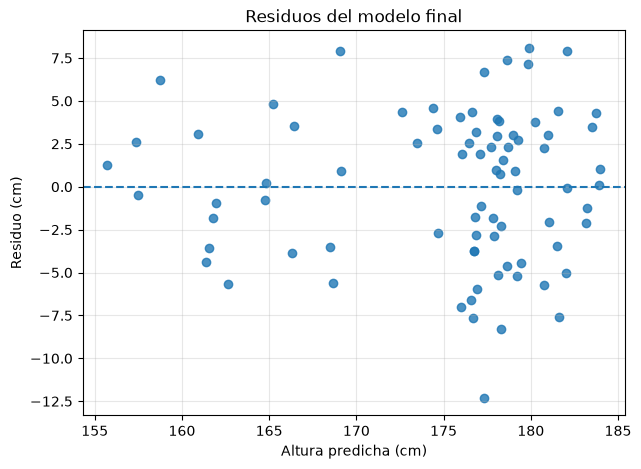

In [37]:
residuos = (datos_modelo["altura_hijo"].to_numpy()-pred_final)

plt.figure(figsize=(7, 5))

plt.scatter(pred_final, residuos, alpha=0.8)

plt.axhline(0, linestyle="--")

plt.xlabel("Altura predicha (cm)")
plt.ylabel("Residuo (cm)")
plt.title("Residuos del modelo final")
plt.grid(alpha=0.3)

plt.show()

Ese es el grafico de residuos del modelo final. Sirve para ver como se distribuyen los errores de las predicciones.

El residuo es:  
- Residuo = altura real - altura predicha

Entonces:
- residuo > 0: el modelo predijo una altura menor a la real
- residuo < 0: el modelo predijo una altura mayor a la real
- residuo = 0: el modelo hizo una buena prediccion